# DoE v3 — conditioned on the data already measured (2026-10)

The v2 design (`doe_design_v2.ipynb`, sliced LHS, w = 0.02, seed 2) was built from scratch: it did not account for the runs the lab has
already measured. This version keeps those runs **fixed** and places the new configurations around them.

**Existing data** — `raw_data/10_26_26/` (identical to the 10_16_26 delivery): the 12 formulations of the August DoE
(`doe/doe_formulations.csv`), all **0x recycled = cycle 0**, 44 tensile specimens. No recycled samples yet.

**Design** — same machinery and objective as the selected v2 design, now on existing + new runs:

* 7 new configurations per polymer (21 in total). Per polymer, PAL % and temperature are cut into 4 + 7 = 11 bands; the existing runs occupy
  4 of them and the new runs take the 7 free ones, so each polymer's 11 runs cover every band once (1 % / 5 °C grid).
* Cycles: cycle 0 already has 4 runs per polymer, so the new runs go to cycles 1–3 (7 / 7 / 7), the most even split of existing + new.
* Objective: `discrepancy (all runs) + mean discrepancy (each polymer) + 0.02 × max |r|` on **existing + new**; best of 10 seeds.

**Layout:** 1 · existing data — 2 · design study (seed study vs v2; comparison with Sobol / plain LHS / optimized LHS, as in the DMREF DoE notebooks) — 3 · the conditioned design (figures) — 4 · replicates — 5 · hand-off.
Logic in `utils/doe.py` (`existing_runs`, `conditioned_sliced_lhs`, `conditioned_seeds`, `compare_conditioned_baselines`), figures in `utils/plots.py`.
**Nothing is written by default.** Each cell that can save has a `SAVE_*` switch and a name.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "utils").exists() and (ROOT.parent / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import config, io, doe, plots

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
p = config.paths(ROOT)

In [2]:
N_PER_POLYMER = 7                 # new configurations per polymer system (3 polymers -> 21)
CORR_WEIGHT = 0.02                # same weight as the selected v2 design
SEEDS = range(10)
PICK_SEED = 9                     # chosen in section 2
RAW = p.root / "raw_data" / "10_26_26"   # delivery holding the existing runs

---
## 1 — Existing data

One row per (formulation, recycle cycle) present in the delivery, with the August DoE factors.

In [3]:
from utils import instron

design_aug = pd.read_csv(p.doe / "doe_formulations.csv")
cat = instron.catalogue(io.extract_zip(RAW))
fixed = doe.existing_runs(design_aug, cat)
print(f"{len(cat)} specimens · {len(fixed)} existing runs · cycles {sorted(fixed['recycle_cycle'].unique())}")
fixed

44 specimens · 12 existing runs · cycles [np.int64(0)]


,formulation,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle,specimens
0,1,HDPE+PAL,49,220,0,3
1,2,HDPE+PAL,23,235,0,4
2,3,PP+PAL,15,225,0,5
3,4,PP+PAL,28,180,0,3
4,5,TPU+PAL,37,230,0,4
5,6,PP+PAL,41,205,0,3
6,7,TPU+PAL,11,200,0,3
7,8,TPU+PAL,46,185,0,4
8,9,HDPE+PAL,35,200,0,3
9,10,HDPE+PAL,19,195,0,4


---
## 2 — Design study

### 2.1 Seed study

Every seed is scored on **existing + new** (33 runs) with the four metrics of the v2 study, as fabricated. `front` marks the designs no other
seed beats on worst within-polymer |r| (↓), fill distance (↓) and min distance (↑), all runs. The last row is the **current plan
(v2, not conditioned) + existing runs** for reference.

In [4]:
SAVE_SEEDS = False                    # True -> write the seed table to doe/<SEEDS_NAME>.xlsx
SEEDS_NAME = "doe_v3_conditioned_seeds"

seeds = doe.conditioned_seeds(fixed, SEEDS, N_PER_POLYMER, CORR_WEIGHT)        # ~2 min per design, in parallel
seeds["front"] = doe.pareto_mask(seeds, minimize=["poly_max_corr", "all_fill_dist"], maximize=["all_min_dist"])
v2 = pd.read_csv(p.doe / "doe_plan_v2.csv").drop(columns=["configuration", "tensile_replicates"])
ref = doe.design_quality(pd.concat([fixed[v2.columns], v2], ignore_index=True))
show = ["seed", "front", "poly_max_corr", "all_fill_dist", "all_min_dist", "all_discrepancy", "poly_discrepancy",
        "poly_fill_dist", "poly_min_dist", "all_max_corr", "recycling_loops"]
seed_tbl = pd.concat([seeds[show], pd.DataFrame([{"seed": "v2 + existing", **ref,
                                                  "recycling_loops": int(v2["recycle_cycle"].sum())}])[
                                                  [c for c in show if c != "front"]]], ignore_index=True)
xlsx = io.save_path(p.doe, SEEDS_NAME, SAVE_SEEDS, ".xlsx")
if xlsx:
    seed_tbl.to_excel(xlsx, index=False)
seed_tbl.round(4)

,seed,front,poly_max_corr,all_fill_dist,all_min_dist,all_discrepancy,poly_discrepancy,poly_fill_dist,poly_min_dist,all_max_corr,recycling_loops
0,0,False,0.0282,0.4322,0.0833,0.0317,0.0412,0.6136,0.3801,0.0080,42
1,1,True,0.0234,0.4296,0.1121,0.0316,0.0393,0.6650,0.3005,0.0153,42
2,2,True,0.0258,0.4709,0.1250,0.0318,0.0408,0.6650,0.1828,0.0078,42
3,3,False,0.0258,0.4709,0.1121,0.0316,0.0406,0.6405,0.3598,0.0080,42
4,4,False,0.0253,0.4449,0.1000,0.0317,0.0392,0.5591,0.3216,0.0103,42
5,5,True,0.0253,0.4173,0.1000,0.0316,0.0400,0.6875,0.2603,0.0129,42
6,6,True,0.0172,0.4449,0.1000,0.0315,0.0393,0.7634,0.3005,0.0134,42
7,7,True,0.0305,0.4053,0.1121,0.0316,0.0414,0.7524,0.3480,0.0240,42
8,8,False,0.0305,0.4178,0.0500,0.0319,0.0410,0.7589,0.1944,0.0195,42
9,9,True,0.0176,0.4384,0.1000,0.0315,0.0411,0.6283,0.3656,0.0089,42


**Reading the seed study** (2026-10-26 run):

* **Conditioning pays off** against v2 + existing: discrepancy of all runs 0.031–0.032 vs 0.084, within each polymer 0.039–0.041 vs 0.099,
  worst within-polymer |r| ≤ 0.031 vs 0.13, within-polymer min distance 0.18–0.38 vs 0.11 (v2 placed new cycle-0 runs next to existing ones,
  e.g. TPU C16 at 43 % / 190 °C beside f08 at 46 % / 185 °C, and one exact duplicate across polymers).
* **The pick: seed 9** — on the front, worst within-polymer |r| 0.018, fill distance 0.438 (all runs) / 0.628 (within polymer), min distance
  0.100 / 0.366: the best within-polymer min distance on the front and the second-best within-polymer fill distance.
* **Cost:** every new run is at cycles 1–3, so **42 recycling loops** (v2: 30).

### 2.2 Comparison with Sobol, plain LHS and optimized LHS

The framework of the DMREF DoE notebooks (`experiment03_hfo2_batch1_analysis`, §7–8): each generator adds 21 new runs to the 12 existing ones,
`len(SEEDS)` seeds each, and **existing + new** is scored on the four metrics as fabricated. As in DMREF's sequential batches, **Sobol** and
**plain LHS** draw a fresh sample (they ignore the existing runs), while the **optimized LHS** is conditioned on them (`conditional_optimized_lhs`:
column swaps of the new block that lower the discrepancy of [existing; new], existing frozen). All three sample (polymer, PAL, temperature, cycle)
in a 4-d cube. The **table** sets the **selected design** (one design, so no ±) against their means; the **chart** shows the method means, with the
conditioned sliced LHS from the seed study, and the star is the selected design.

In [5]:
SAVE_METRICS = False                  # True -> write the per-seed metrics to doe/<METRICS_NAME>.xlsx
METRICS_NAME = "doe_v3_method_metrics"

sliced_name = f"Sliced LHS (conditioned, w = {CORR_WEIGHT:g})"
pick_name = f"{sliced_name}, seed {PICK_SEED} (selected)"
qcols = [c for c in seeds.columns if c.startswith(("all_", "poly_"))] + ["runs_per_polymer", "polymers_missing_a_cycle"]
base = doe.compare_conditioned_baselines(fixed, n_seeds=len(SEEDS), n_new=3 * N_PER_POLYMER)
tbl = pd.concat([base, seeds[["seed"] + qcols].assign(method=sliced_name)], ignore_index=True)
picked = seeds.set_index("seed").loc[PICK_SEED, qcols].to_dict()
tbl_pick = pd.concat([base, pd.DataFrame([{"method": pick_name, "seed": PICK_SEED, **picked}])], ignore_index=True)
summary, best = doe.method_summary(tbl_pick)          # bold = best per row; ties all bold
styled = summary.T.style.apply(lambda _: np.where(best.T, "font-weight: bold", ""), axis=None)
xlsx = io.save_path(p.doe, METRICS_NAME, SAVE_METRICS, ".xlsx")
if xlsx:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        tbl.to_excel(xw, sheet_name="per_seed", index=False)
        styled.to_excel(xw, sheet_name="summary")
styled

method,Sobol,Plain LHS,Optimized LHS (conditioned),"Sliced LHS (conditioned, w = 0.02), seed 9 (selected)"
all_discrepancy ↓,0.0809 ± 0.0054,0.0777 ± 0.0034,0.0718 ± 0.0026,0.0315
all_min_dist ↑,0.0607 ± 0.028,0.0583 ± 0.0334,0.0633 ± 0.0292,0.1
all_max_corr ↓,0.1378 ± 0.0522,0.1799 ± 0.0928,0.0534 ± 0.0173,0.0089
all_fill_dist ↓,0.4553 ± 0.0224,0.5432 ± 0.1075,0.4422 ± 0.0137,0.4384
poly_discrepancy ↓,0.1441 ± 0.0288,0.1634 ± 0.0318,0.2858 ± 0.0388,0.0411
poly_min_dist ↑,0.1065 ± 0.0529,0.0728 ± 0.0288,0.0633 ± 0.0292,0.3656
poly_max_corr ↓,0.4402 ± 0.124,0.4604 ± 0.0576,0.4778 ± 0.1279,0.0176
poly_fill_dist ↓,0.8421 ± 0.1039,0.9203 ± 0.0782,1.0377 ± 0.0435,0.6283
runs per polymer (min-max; equal = balanced),"10-12, 10-13, 11-11, 9-12",11-11,11-11,11-11
seeds with a polymer missing a cycle ↓,5,6,10,0


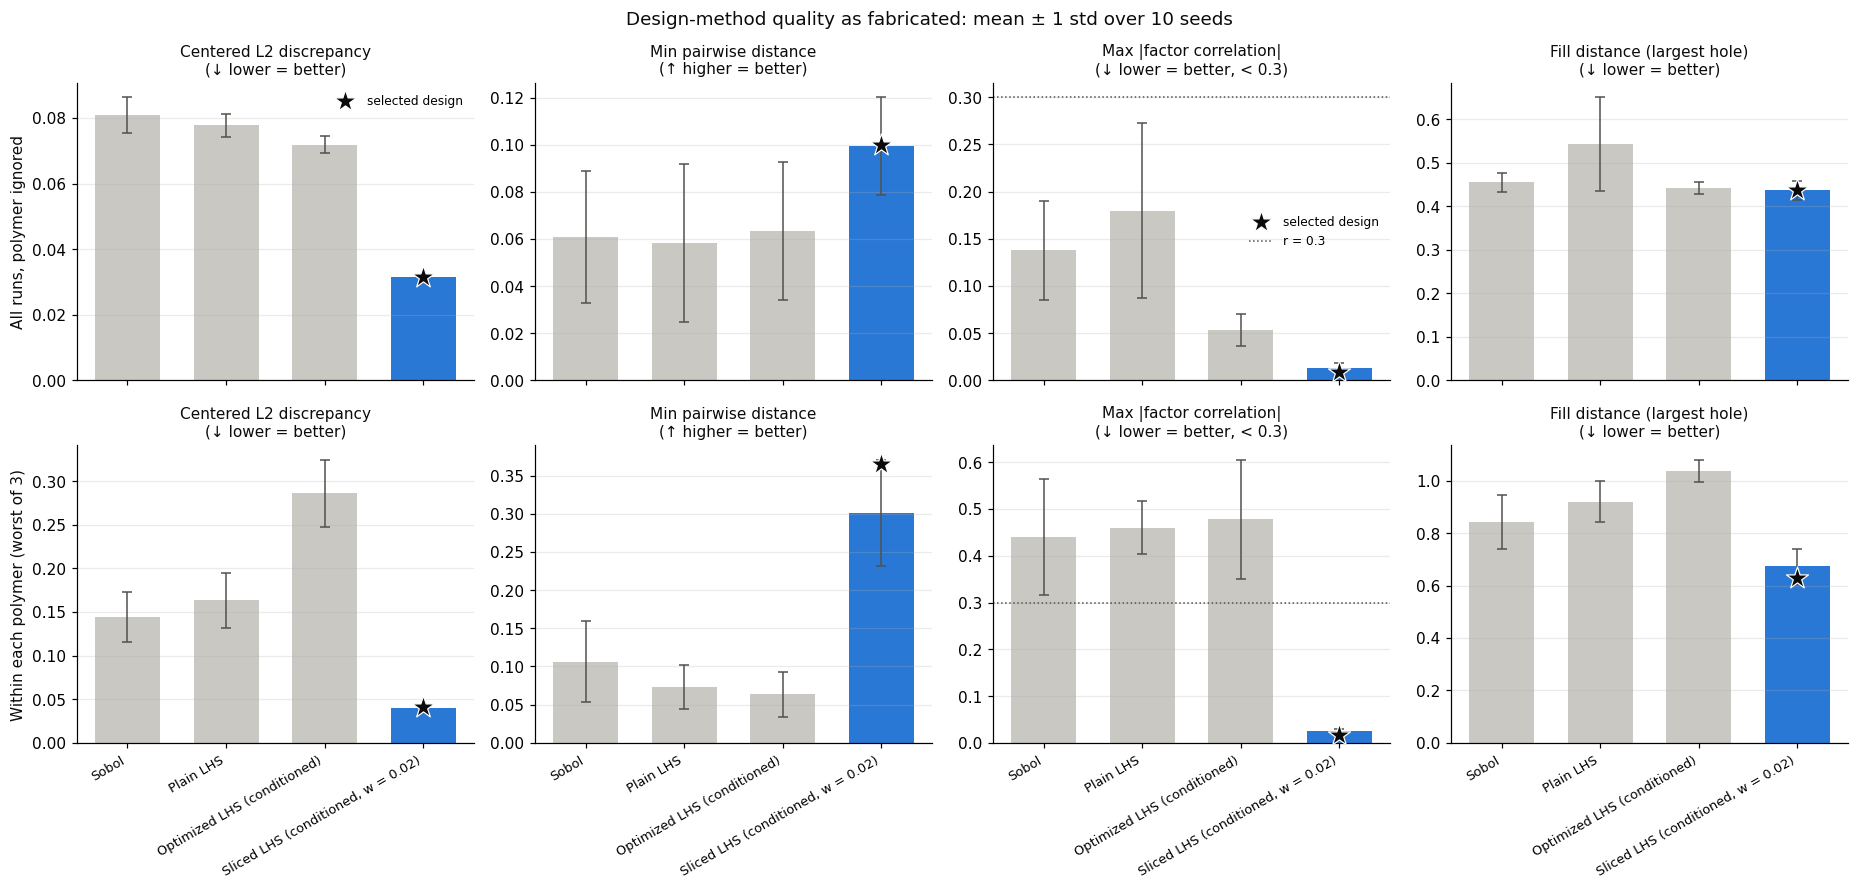

In [6]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v3_method_comparison"

plots.design_method_comparison(tbl, picked, used_method=sliced_name,
                               save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Reading the comparison** (existing + new, 2026-10-27 run): the selected design wins every row. Within each polymer the gap is large —
discrepancy 0.041 vs 0.14–0.29, worst |r| 0.018 vs 0.44–0.48, min distance 0.37 vs 0.06–0.11, fill distance 0.63 vs 0.84–1.04 — and over all runs
discrepancy is 0.032 vs 0.072–0.081 with the best min and fill distances. The conditioned optimized LHS improves the all-runs discrepancy over
Sobol / plain LHS but is the worst within each polymer and leaves a polymer without a cycle in all 10 seeds: its 4-d discrepancy treats the polymer
as a continuous axis and, with the existing runs all at cycle 0, does not balance the cycles per polymer. Sobol also unbalances the polymers
(9–13 runs instead of 11).

---
## 3 — The conditioned design (for the lab)

The 21 new configurations; together with the 12 existing runs, every polymer has 11 runs that cover each PAL and temperature band once.

In [7]:
new, quality = doe.conditioned_sliced_lhs(fixed, N_PER_POLYMER, corr_weight=CORR_WEIGHT, seed=PICK_SEED)
union = pd.concat([fixed[["polymer_system", "PAL_pct", "extrusion_temp_C", "recycle_cycle"]].assign(run="existing"),
                   new.drop(columns="configuration").assign(run="new")], ignore_index=True)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in quality.items()})
new

{'n_new': 21, 'n_fixed': 12, 'per_cycle_new': {1: 7, 2: 7, 3: 7}, 'per_cycle_all': {0: 12, 1: 7, 2: 7, 3: 7}, 'cd_pooled': 0.0141, 'cd_slices': 0.0195, 'max_abs_corr': 0.0089, 'max_abs_corr_slices': 0.0176, 'objective': 0.034, 'objective_random_start': 0.0469, 'recycling_loops': 42}


,configuration,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle
0,1,PP+PAL,20,210,1
1,2,PP+PAL,45,215,1
2,3,PP+PAL,22,220,2
3,4,PP+PAL,33,200,2
4,5,PP+PAL,48,195,2
5,6,PP+PAL,12,190,3
6,7,PP+PAL,38,235,3
7,8,HDPE+PAL,13,210,1
8,9,HDPE+PAL,30,205,1
9,10,HDPE+PAL,44,190,1


In [8]:
pd.crosstab([union["polymer_system"], union["run"]], union["recycle_cycle"], margins=True)

recycle_cycle             0  1  2  3  All
polymer_system run                       
HDPE+PAL       existing   4  0  0  0    4
               new        0  3  2  2    7
PP+PAL         existing   4  0  0  0    4
               new        0  2  3  2    7
TPU+PAL        existing   4  0  0  0    4
               new        0  2  2  3    7
All                      12  7  7  7   33

**Configurations in design space** — shape = polymer, colour = recycle cycle; hollow = existing data (cycle 0), filled = new configurations.

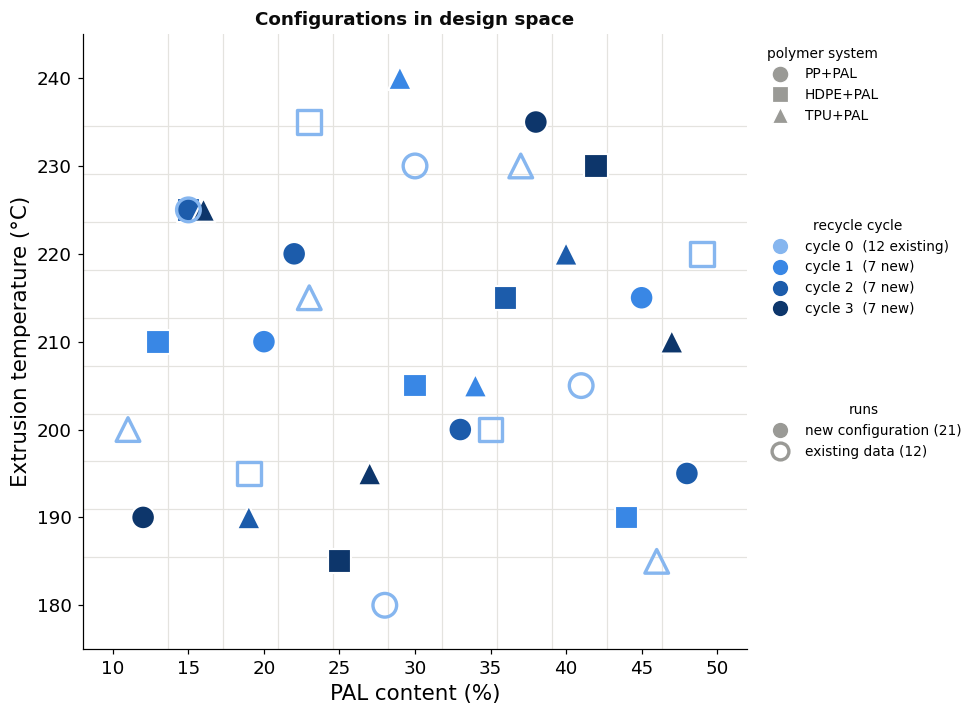

In [9]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v3_design_space"

plots.doe_design_space(new, color_by="cycle", existing=union[union["run"] == "existing"],
                       save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

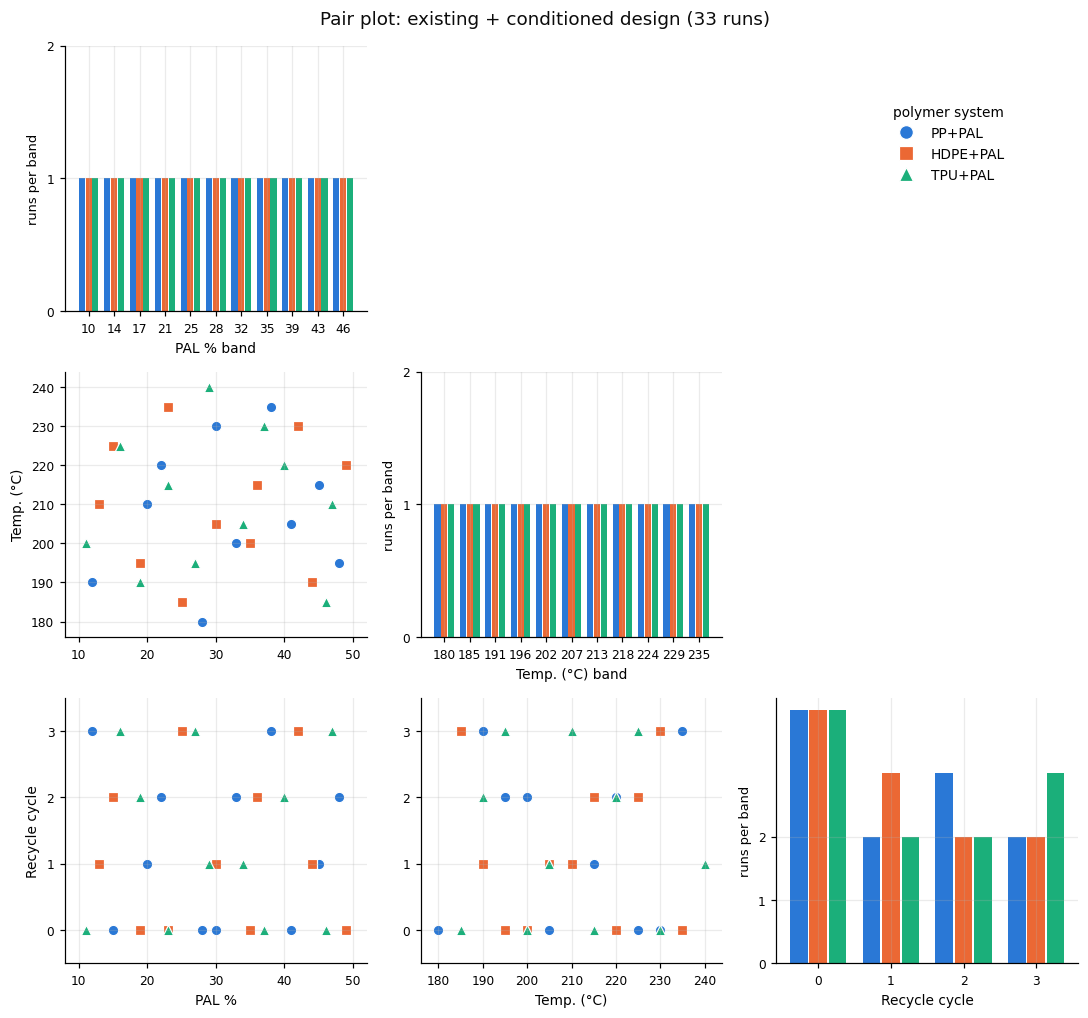

In [10]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v3_pairs"

plots.doe_pairs(union, title=f"Pair plot: existing + conditioned design ({len(union)} runs)",
                save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

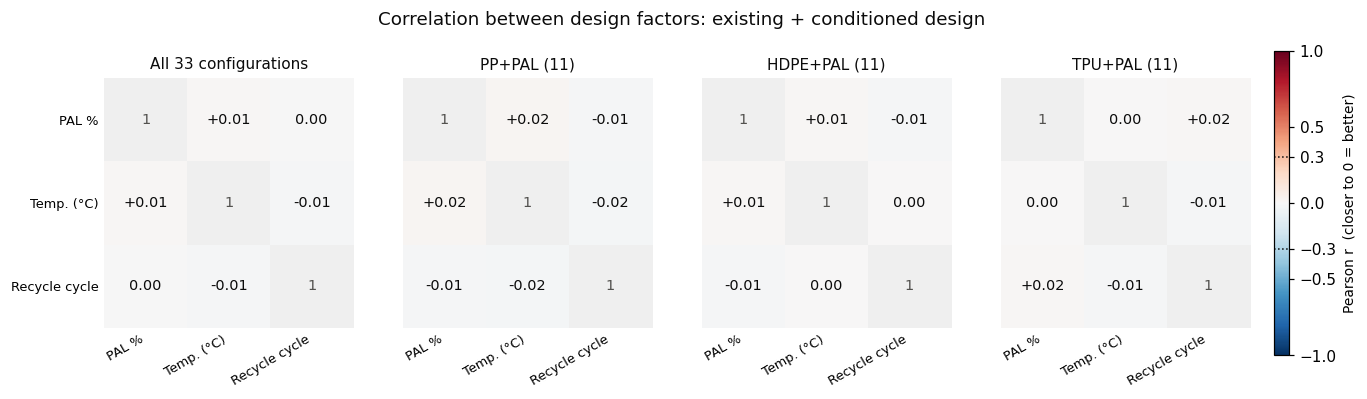

In [11]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_v3_correlation"

plots.doe_correlation(union, title="Correlation between design factors: existing + conditioned design",
                      save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

---
## 4 — Replicates and the specimen log

**Why 5 and not 3.** The data has n = 3 per configuration, where:

* the IQR fences always enclose all 3 points (Q1 = (a+b)/2, Q3 = (b+c)/2 put the upper fence at or above c), so no point is ever flagged; Dixon's Q
  needs Q > 0.970 at n = 3, i.e. the other two specimens almost identical;
* scaling by the configuration's own SD is bounded (max |studentized residual| = 2/√3 ≈ 1.155), so "noisy configuration" and "one bad specimen"
  look the same, and heteroscedasticity cannot be estimated per configuration;
* dropping one specimen leaves 2.

With 5: within-configuration screening works (Dixon's Q critical value 0.710), the per-configuration variance has 4 degrees of freedom (needed by
the heteroscedastic-noise model), and 4 specimens remain after an exclusion. Previously delivered data (3 replicates) is kept as is and screened on
pooled log-scale residuals.

**Specimen log.** One row per specimen with blanks for the lab: test date, data rate, measured diameter, break location, notes. An odd
specimen is excluded only for a physical reason (slip, break at the grip, defect), and this is where that reason is recorded. The June
Config16 (100 % PP, 200 °C) case shows why: specimens 1–3 vs 4–5 were evidently acquired at different settings.

In [12]:
REPLICATES = 5
log = doe.specimen_log(new, replicates=REPLICATES)
print(f"{len(new)} configurations x {REPLICATES} = {len(log)} tensile specimens · "
      f"{quality['recycling_loops']} recycling loops · {len(new)} formulations to compound")
log.head(7)

21 configurations x 5 = 105 tensile specimens · 42 recycling loops · 21 formulations to compound


,specimen_id,configuration,replicate,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle,test_date,data_rate_Hz,diameter_mm,break_location,notes
0,C01_1,1,1,PP+PAL,20,210,1,,,,,
1,C01_2,1,2,PP+PAL,20,210,1,,,,,
2,C01_3,1,3,PP+PAL,20,210,1,,,,,
3,C01_4,1,4,PP+PAL,20,210,1,,,,,
4,C01_5,1,5,PP+PAL,20,210,1,,,,,
5,C02_1,2,1,PP+PAL,45,215,1,,,,,
6,C02_2,2,2,PP+PAL,45,215,1,,,,,


---
## 5 — Hand-off workbook

Same layout as `doe/doe_plan_v2.xlsx` (`configurations`, `specimen_log`, `notes`), plus an `existing_runs` sheet. v2 files are left untouched.

In [13]:
SAVE_XLSX = False                     # True -> write doe/<XLSX_NAME>.xlsx
XLSX_NAME = "doe_plan_v3_conditioned"
SAVE_CSV = False                      # True -> write the configurations to doe/<CSV_NAME>.csv
CSV_NAME = "doe_plan_v3_conditioned"

configurations = new.assign(tensile_replicates=REPLICATES)
notes = pd.DataFrame({"item": [
    "configuration", "existing runs", "polymer_system", "PAL_pct", "extrusion_temp_C", "recycle_cycle",
    "tensile_replicates", "file names", "specimen_log", "processing window"], "note": [
    "C01-C21; new numbering, independent of the August formulations f01-f12",
    "designed around the 12 August formulations already tested at cycle 0 (sheet existing_runs); they are not repeated",
    "PP+PAL, HDPE+PAL or TPU+PAL; 7 configurations each",
    "PAL content in %, range 10-50",
    "extrusion temperature in degC, range 180-240, 5 degC grid",
    "0 = as extruded (no recycling); 1-3 = number of recycling loops. All new configurations are at cycles 1-3. We assume every loop uses the configuration's extrusion temperature; please tell us if not",
    "5 tensile specimens per configuration",
    "please name each test file by configuration and replicate, e.g. C07_3",
    "please fill in test date, data rate (Hz), measured diameter (mm), break location (gauge / near grip / in grip) and anything unusual (slip, voids)",
    "if a configuration is outside what a polymer can be processed at, tell us and we will move it"]})

xlsx = io.save_path(p.doe, XLSX_NAME, SAVE_XLSX, ".xlsx")
if xlsx:
    with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
        configurations.to_excel(xw, sheet_name="configurations", index=False)
        log.to_excel(xw, sheet_name="specimen_log", index=False)
        fixed.to_excel(xw, sheet_name="existing_runs", index=False)
        notes.to_excel(xw, sheet_name="notes", index=False)
csv = io.save_path(p.doe, CSV_NAME, SAVE_CSV, ".csv")
if csv:
    configurations.to_csv(csv, index=False)
print("written:", [str(x) for x in (xlsx, csv) if x] or "nothing (switches off)")
configurations

written: nothing (switches off)


,configuration,polymer_system,PAL_pct,extrusion_temp_C,recycle_cycle,tensile_replicates
0,1,PP+PAL,20,210,1,5
1,2,PP+PAL,45,215,1,5
2,3,PP+PAL,22,220,2,5
3,4,PP+PAL,33,200,2,5
4,5,PP+PAL,48,195,2,5
5,6,PP+PAL,12,190,3,5
6,7,PP+PAL,38,235,3,5
7,8,HDPE+PAL,13,210,1,5
8,9,HDPE+PAL,30,205,1,5
9,10,HDPE+PAL,44,190,1,5
